In [67]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

import astropy.coordinates as coord
import astropy.units as u
from astropy.table import Table

import gala.dynamics as gd
import gala.potential as gp

%config InlineBackend.figure_format = 'retina'

In [4]:
t = Table.read('../data/gmc_catalog.txt', format="ascii.cds")

In [5]:
t

Cloud,Ncomp,Npix,A,l,e_l,b,e_b,theta,WCO,NH2,Sigma,vcent,sigmav,Rmax,Rmin,Rang,Rgal,INF,Dn,Df,zn,zf,Sn,Sf,Rn,Rf,Mn,Mf
,,,deg2,deg,deg,deg,deg,deg,K km / s,1 / cm2,Msun / pc2,km / s,km / s,deg,deg,deg,kpc,,kpc,kpc,kpc,kpc,pc2,pc2,pc,pc,Msun,Msun
int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
1,6,6,0.09375,-0.5607162,0.1539333,0.06382389,0.125,28.80217,257.1223,8.570743e+21,186.8806,-151.3869,16.56749,0.3547774,0.125,0.1769805,0.1017339,1,8.441028,8.558167,0.009402772,0.009533258,2034.783,2091.65,26.0735,26.43534,380261.5,390888.8
2,20,20,0.3125,-0.2775763,0.1846381,-0.2414595,0.1387891,10.75815,1115.18,1.11518e+22,243.1592,-147.0932,14.3163,0.3822154,0.2594724,0.2952321,0.0507952,1,8.470236,8.529715,-0.03569569,-0.03594635,6829.629,6925.883,43.64558,43.95206,1660687.0,1684092.0
3,25,25,0.390625,-0.8570029,0.1949344,-0.2594873,0.1474836,-17.89513,1439.139,1.151311e+22,251.0375,-132.4169,14.6353,0.4223319,0.24625,0.2947602,0.1798826,1,8.371877,8.626396,-0.03791533,-0.03906802,8339.919,8854.724,43.0698,44.37919,2093632.0,2222868.0
4,107,87,1.359375,-19.65611,0.3216265,-0.09603355,0.2715381,9.468965,856.8566,1.969785e+21,42.95015,-123.6221,5.4785,0.6673993,0.5131125,0.5601062,3.105224,0,6.793293,9.216113,-0.01138624,-0.01544713,19109.8,35171.51,66.41129,90.0968,820768.8,1510622.0
5,46,45,0.703125,-0.4374006,0.2722614,-0.316237,0.2026764,9.319308,2062.619,9.167195e+21,199.886,-110.569,15.17498,0.5590021,0.38514,0.436064,0.1088423,1,8.412497,8.587267,-0.04643151,-0.04739613,15157.88,15794.23,64.02666,65.35682,3029847.0,3157046.0
6,12,12,0.1875,-0.4372361,0.1654708,-0.04790194,0.1405083,-29.76107,614.858,1.024763e+22,223.4443,-102.6608,14.18503,0.3983814,0.1725829,0.2280857,0.1173931,1,8.40191,8.5976,-0.007024386,-0.007187992,4031.935,4221.938,33.4469,34.22591,900912.9,943368.2
7,53,44,0.6875,-31.698,0.1469414,0.5639032,0.3120525,-10.87805,744.1021,3.382282e+21,73.74891,-96.88103,6.236558,0.6248305,0.2923372,0.3765681,4.580731,0,6.214683,8.250117,0.06116371,0.08119606,8088.478,14254.4,40.84568,54.22347,596516.4,1051247.0
8,97,75,1.171875,-28.94289,0.2059972,0.04247036,0.3242863,12.73058,1401.988,3.738635e+21,81.519,-95.35374,7.169594,0.6529751,0.4049807,0.474885,4.436034,0,5.777722,9.099026,0.004282722,0.00674463,11916.56,29554.74,47.88863,75.41724,971425.6,2409273.0


In [6]:
N = len(t)

In [7]:
dist = np.empty(N, dtype=float) * u.kpc

In [49]:
dist[t['INF']==0] = t['Dn'][t['INF']==0]
dist[t['INF']==1] = t['Df'][t['INF']==1]

In [50]:
c = coord.Galactic(l=t['l'], b=t['b'], distance=dist)

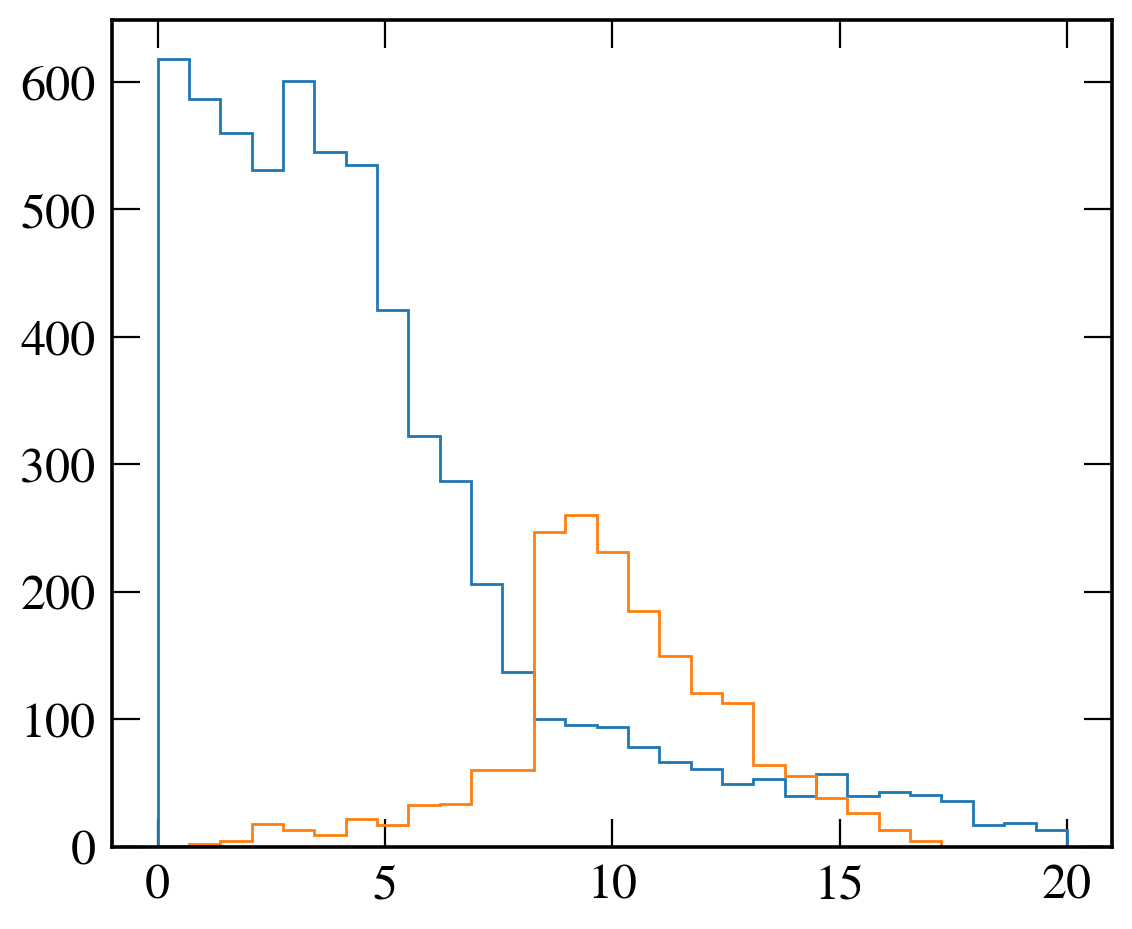

In [56]:
plt.figure(figsize=(6,5))

plt.hist(t['Dn'][t['INF']==0], bins=np.linspace(0,20,30), histtype='step',)
plt.hist(t['Df'][t['INF']==1], bins=np.linspace(0,20,30), histtype='step')

plt.tight_layout()

In [51]:
cgal = c.transform_to(coord.Galactocentric())

In [52]:
np.array(cgal.x[:])

array([  0.4357748 ,   0.40744581,   0.50324084, ..., -16.31763882,
       -19.3333554 ,  -1.44880602], shape=(8107,))

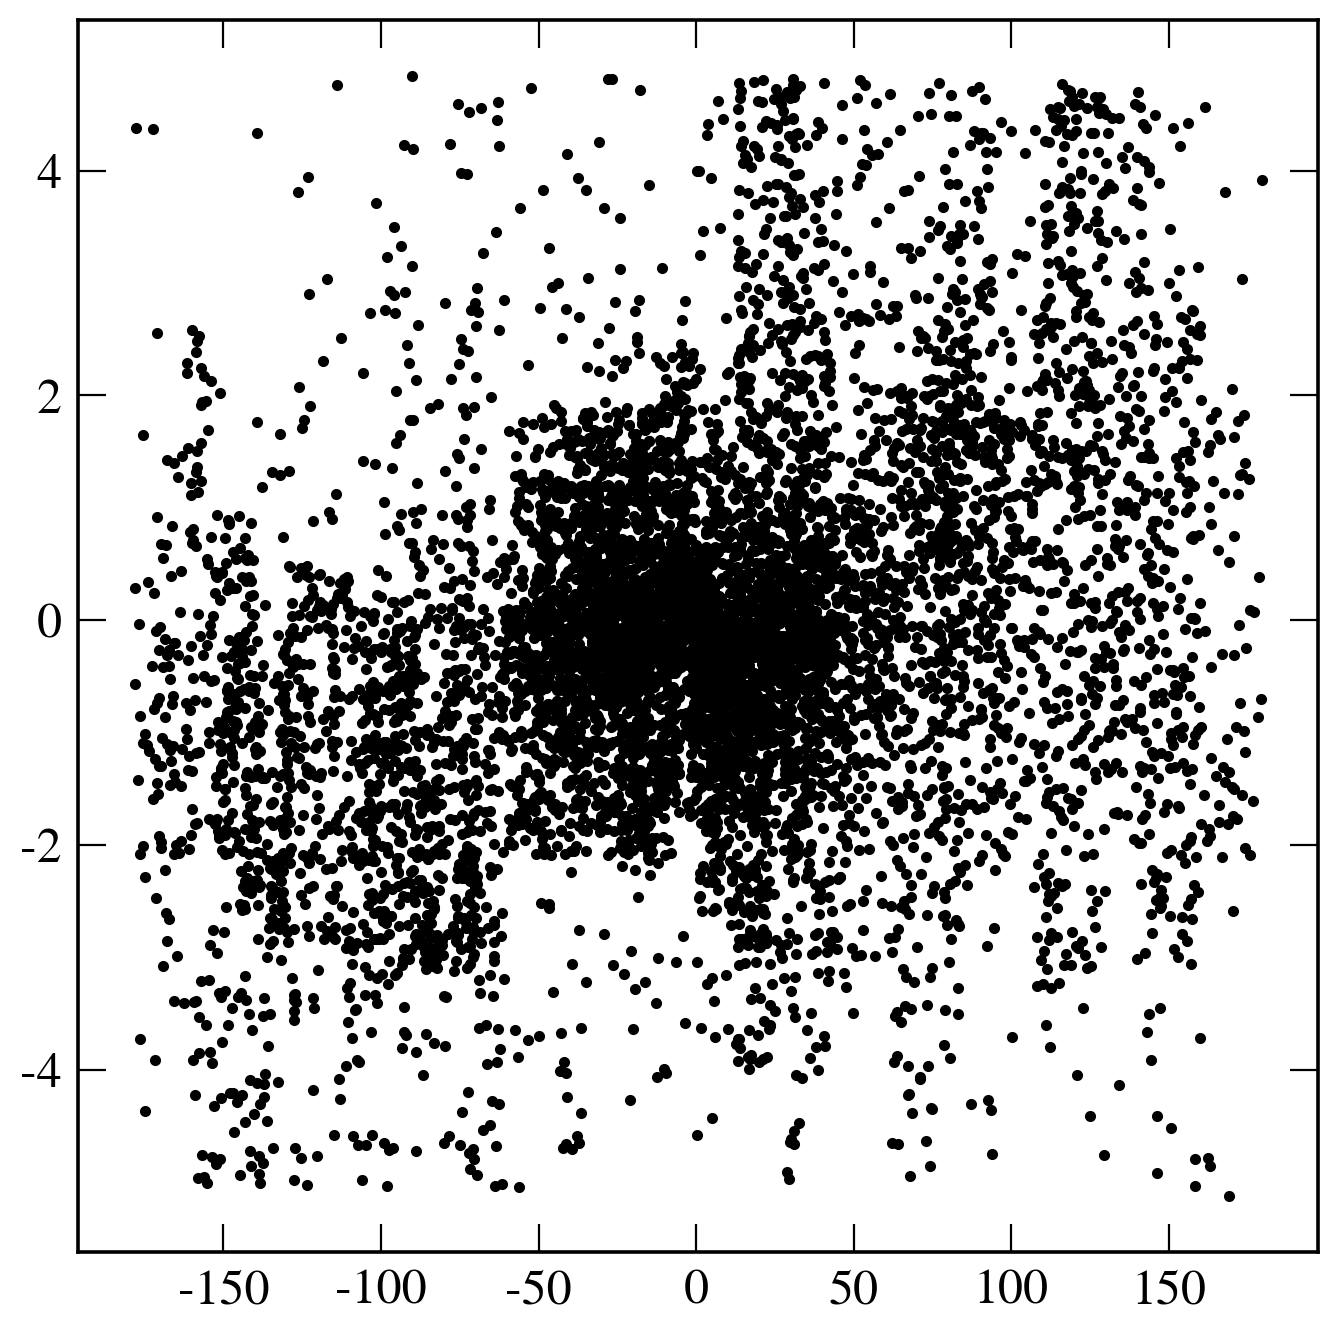

In [53]:
plt.plot(t['l'], t['b'], 'k.')

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


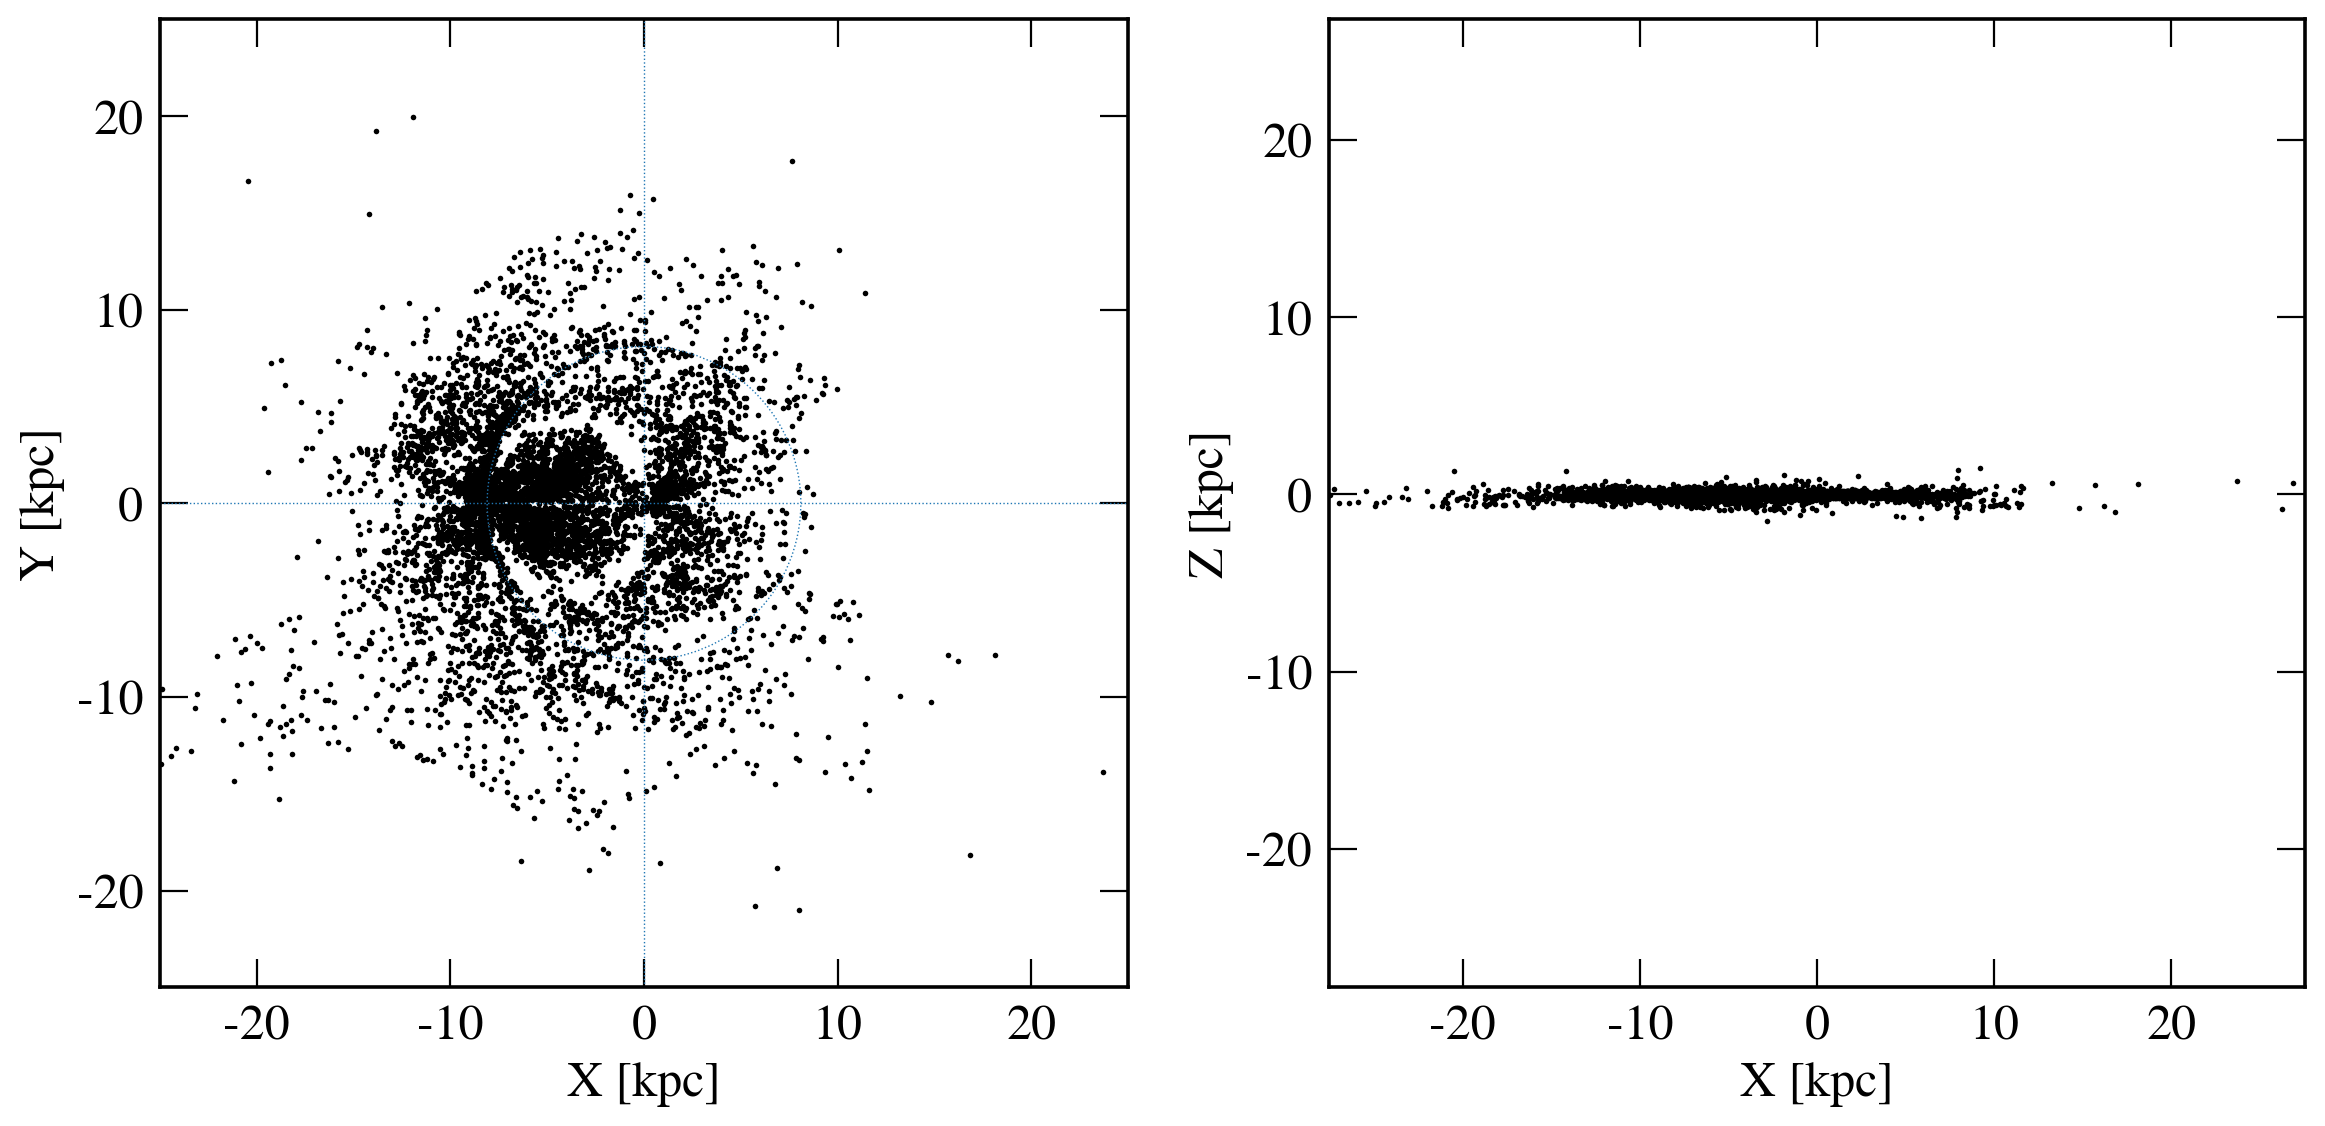

In [73]:
fig, ax = plt.subplots(1,2,figsize=(12,6))

plt.sca(ax[0])
plt.plot(cgal.x, cgal.y, 'ko', ms=2, mew=0, zorder=0)

plt.axhline(0, lw=0.5, ls=':')
plt.axvline(0, lw=0.5, ls=':')

circle = matplotlib.patches.Circle((0, 0), 8.1, ec='tab:blue', fc='none', ls=':', lw=0.5)
plt.gca().add_patch(circle)

plt.xlim(-25, 25)
plt.ylim(-25, 25)
plt.gca().set_aspect('equal')

plt.xlabel('X [kpc]')
plt.ylabel('Y [kpc]')

plt.sca(ax[1])
plt.plot(cgal.x, cgal.z, 'ko', ms=2, mew=0, zorder=0)

plt.gca().set_aspect('equal', adjustable='datalim')

plt.xlabel('X [kpc]')
plt.ylabel('Z [kpc]')
plt.xlim(-25, 25)

plt.tight_layout()

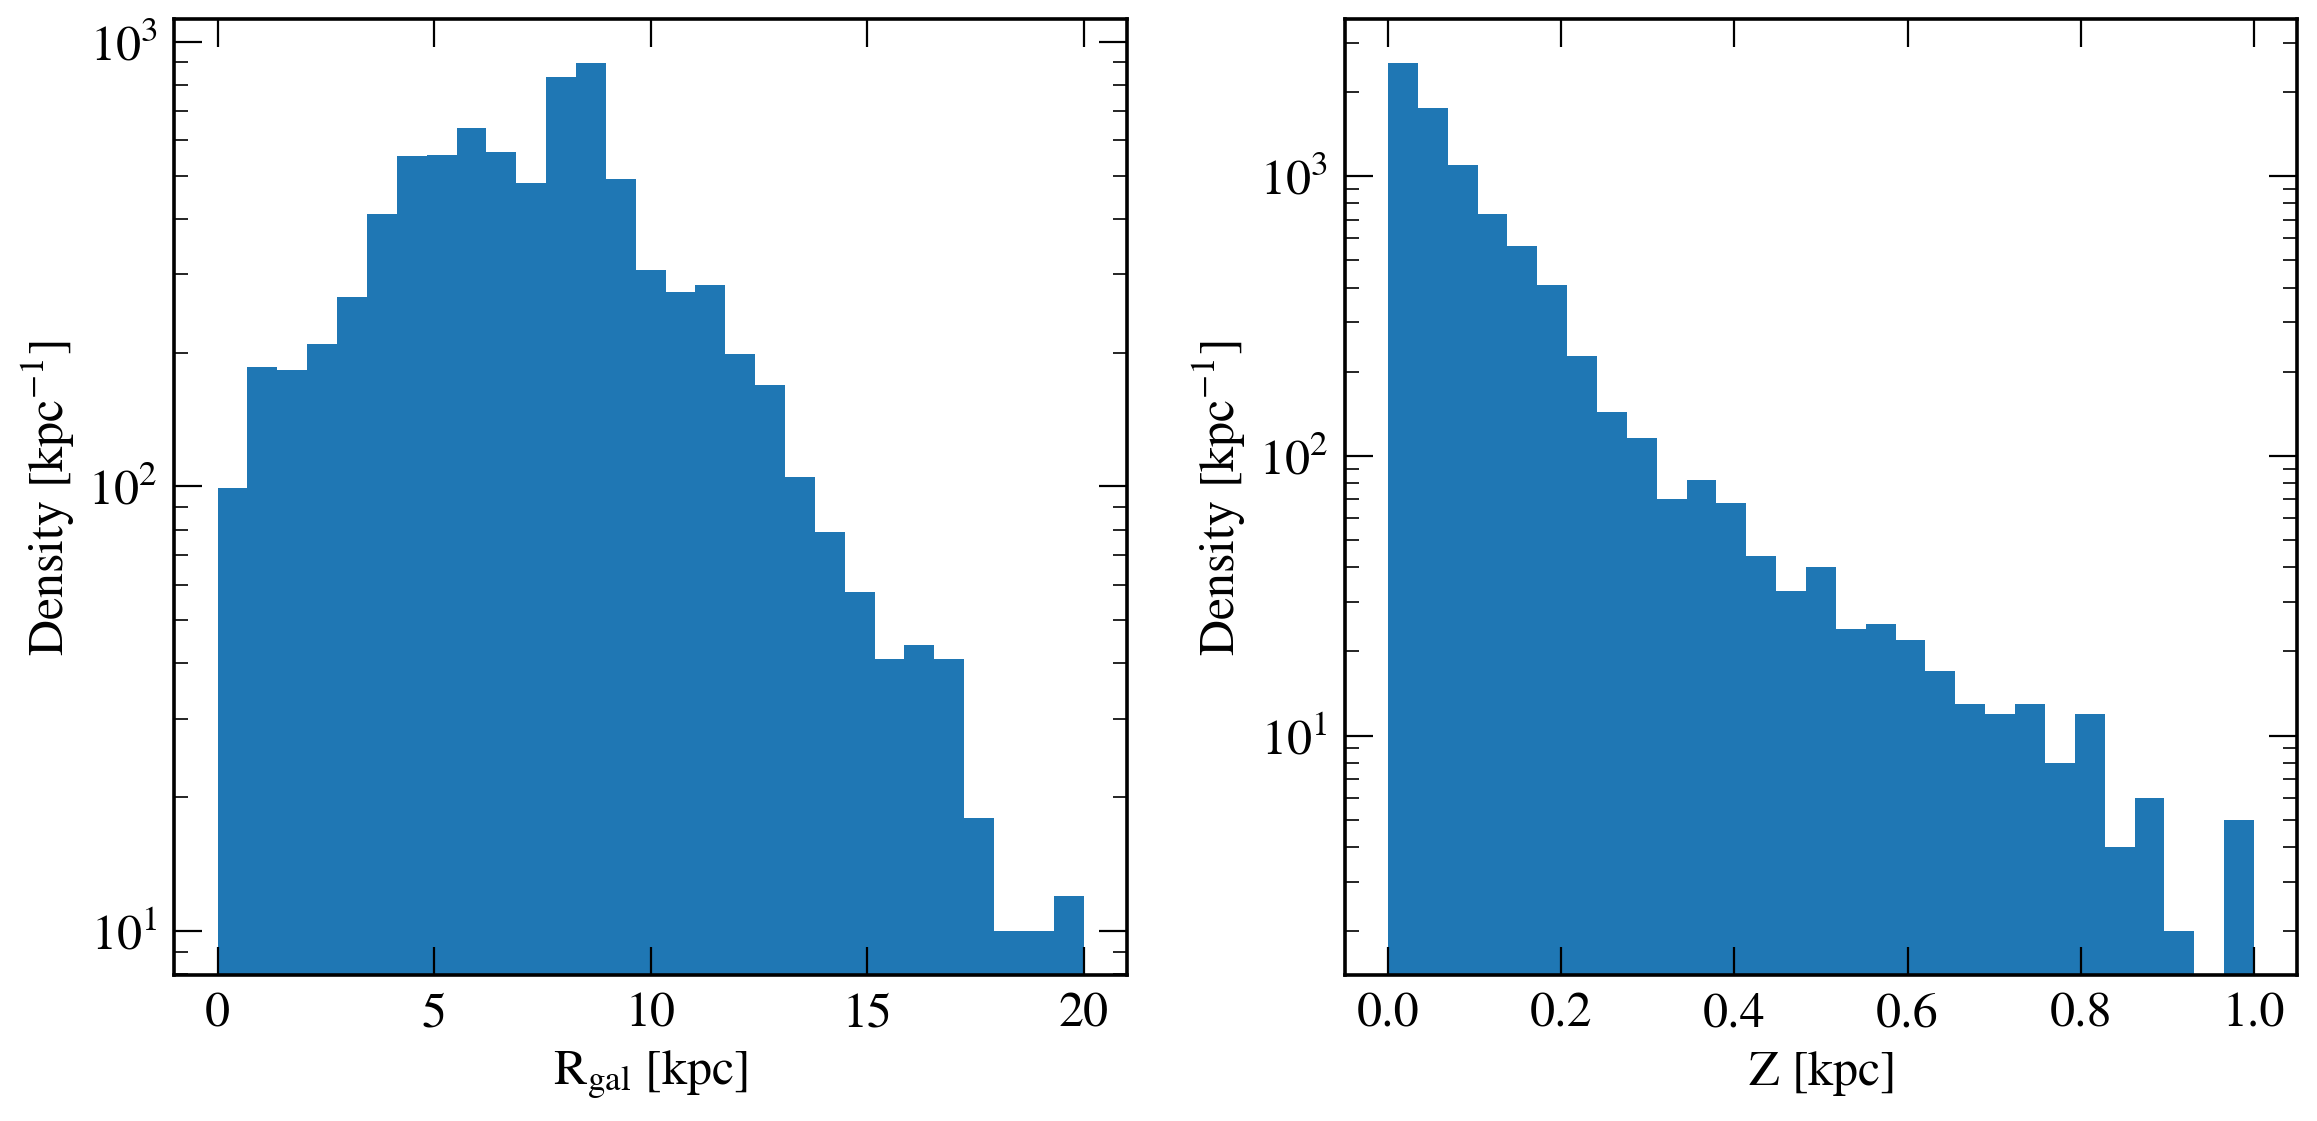

In [78]:
fig, ax = plt.subplots(1,2,figsize=(12,6))

plt.sca(ax[0])
plt.hist(cgal.spherical.distance.value, bins=np.linspace(0,20,30))
plt.gca().set_yscale('log')

plt.xlabel('$R_{gal}$ [kpc]')
plt.ylabel('Density [kpc$^{-1}$]')

plt.sca(ax[1])
plt.hist(np.abs(cgal.z.value), bins=np.linspace(0,1,30))
plt.gca().set_yscale('log')

plt.xlabel('$Z$ [kpc]')
plt.ylabel('Density [kpc$^{-1}$]')

plt.tight_layout()